# Malaria Cell Classification

Binary classification of segmented blood cell images (parasitized vs uninfected) with a retrainable pipeline.

In [1]:
import os
import sys
import zipfile
from pathlib import Path
from google.colab import files

uploaded = files.upload()
with zipfile.ZipFile(next(iter(uploaded))) as bundle:
    bundle.extractall("/content")

root = Path("/content/malaria-classifier")
os.chdir(root)
sys.path.insert(0, str(root))

Saving malaria-classifier.zip to malaria-classifier.zip


In [2]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(ROOT))

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from PIL import Image
from sklearn import metrics as skm

from src import config
from src import model as M
from src import preprocessing as P
from src import retrain as R

tf.keras.utils.set_random_seed(config.SEED)
sns.set_theme(style="whitegrid")
print(tf.__version__, keras.__version__)

2.21.0 3.13.2


In [3]:
P.download_dataset()
P.split_dataset()

train_paths, train_labels = P.list_labelled_files(config.TRAIN_DIR)
test_paths, test_labels = P.list_labelled_files(config.TEST_DIR)
names = dict(enumerate(config.CLASS_NAMES))

counts = pd.DataFrame(
    {
        "train": pd.Series(train_labels).map(names).value_counts(),
        "test": pd.Series(test_labels).map(names).value_counts(),
    }
)
counts

,train,test
uninfected,11024,2755
parasitized,11024,2755


Class balance across the train and test splits.

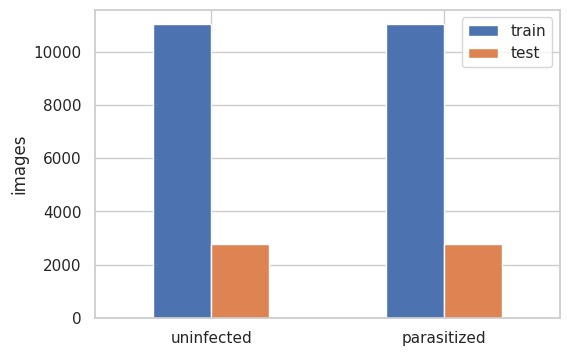

In [4]:
counts.plot(kind="bar", figsize=(6, 4))
plt.ylabel("images")
plt.xticks(rotation=0)
plt.show()

Random cells from each class (top row parasitized, bottom row uninfected).

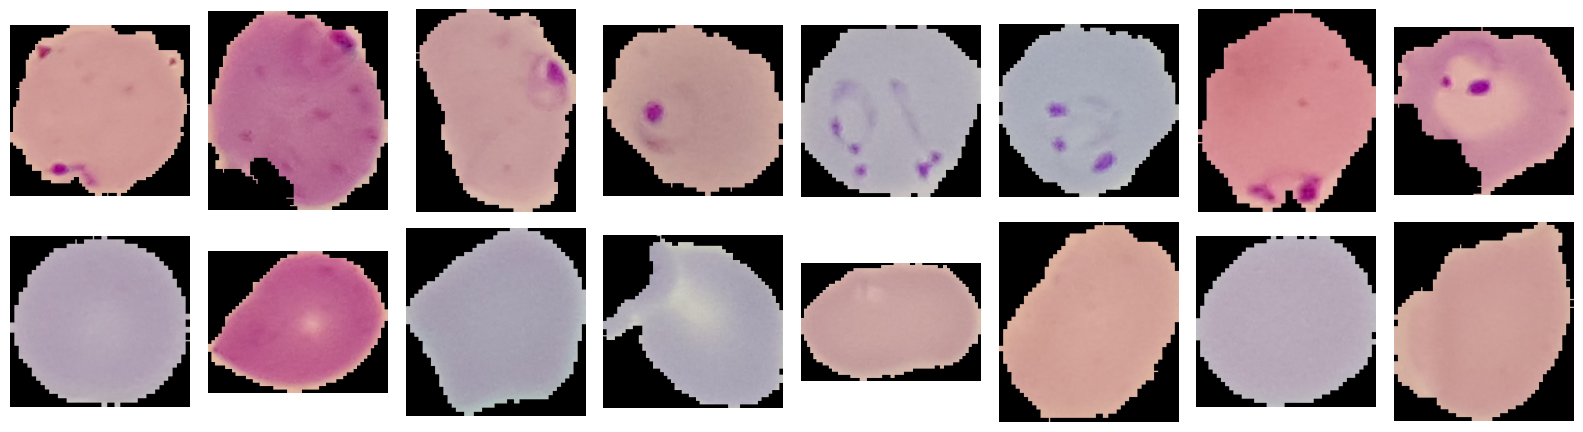

In [5]:
rng = np.random.default_rng(config.SEED)
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for row, label in enumerate((1, 0)):
    pool = [p for p, l in zip(train_paths, train_labels) if l == label]
    for ax, path in zip(axes[row], rng.choice(pool, 8, replace=False)):
        ax.imshow(Image.open(path))
        ax.axis("off")
plt.tight_layout()
plt.show()

Per-image features measured on cell pixels only (the black background is excluded): dimensions, channel means, saturation and the fraction of low-green (stained) pixels.

In [6]:
rng = np.random.default_rng(config.SEED)
rows = []
for label, name in enumerate(config.CLASS_NAMES):
    pool = [p for p, l in zip(train_paths, train_labels) if l == label]
    for path in rng.choice(pool, 1500, replace=False):
        rows.append({"class": name, **P.image_features(path)})
features = pd.DataFrame(rows)
features.groupby("class").mean().round(3).T

class,parasitized,uninfected
width,133.630,131.478
height,134.656,132.358
cell_fraction,0.710,0.724
mean_r,189.936,188.301
mean_g,145.587,155.991
mean_b,157.944,164.115
saturation,0.260,0.203
stain_fraction,0.045,0.005


Width and height by class. Every image is resized to 128x128 before training.

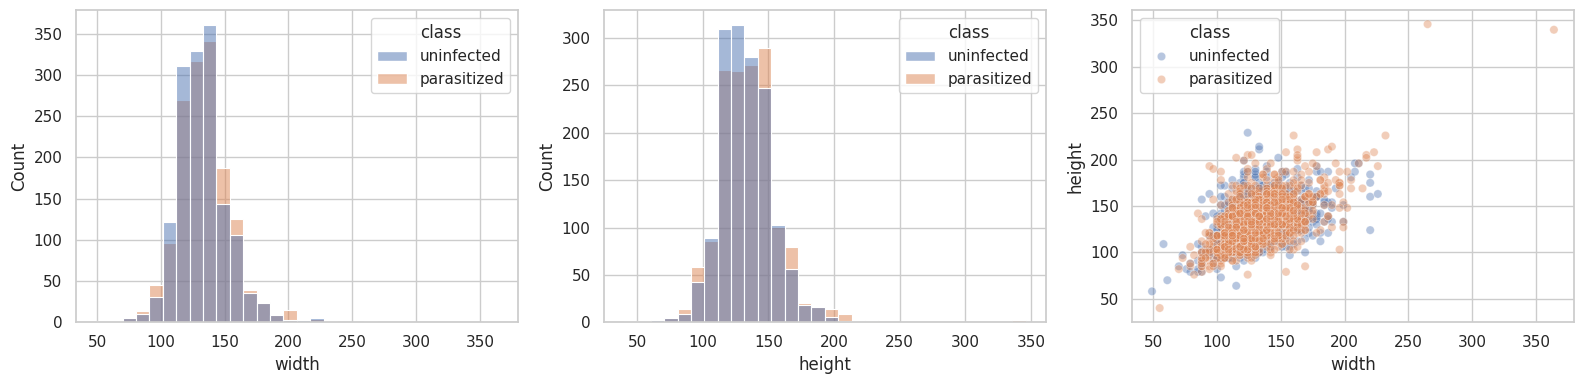

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(data=features, x="width", hue="class", bins=30, ax=axes[0])
sns.histplot(data=features, x="height", hue="class", bins=30, ax=axes[1])
sns.scatterplot(data=features, x="width", y="height", hue="class", alpha=0.4, ax=axes[2])
plt.tight_layout()
plt.show()

Mean red, green and blue intensity over cell pixels, by class.

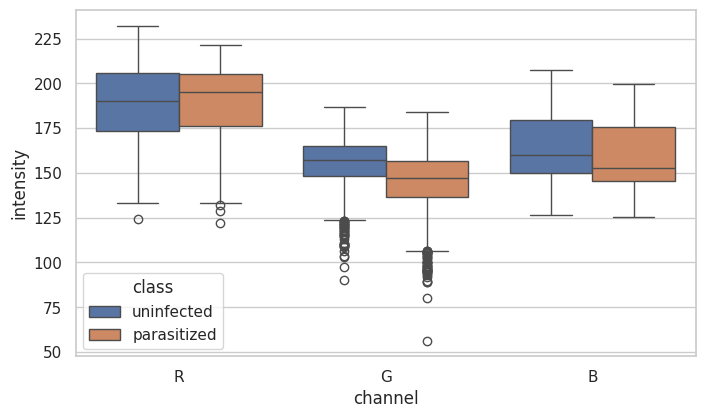

In [8]:
channels = features.melt(
    id_vars="class", value_vars=["mean_r", "mean_g", "mean_b"], var_name="channel", value_name="intensity"
)
channels["channel"] = channels["channel"].str[-1].str.upper()
plt.figure(figsize=(8, 4.5))
sns.boxplot(data=channels, x="channel", y="intensity", hue="class")
plt.show()

Fraction of stained (low-green) cell pixels and mean saturation, by class.

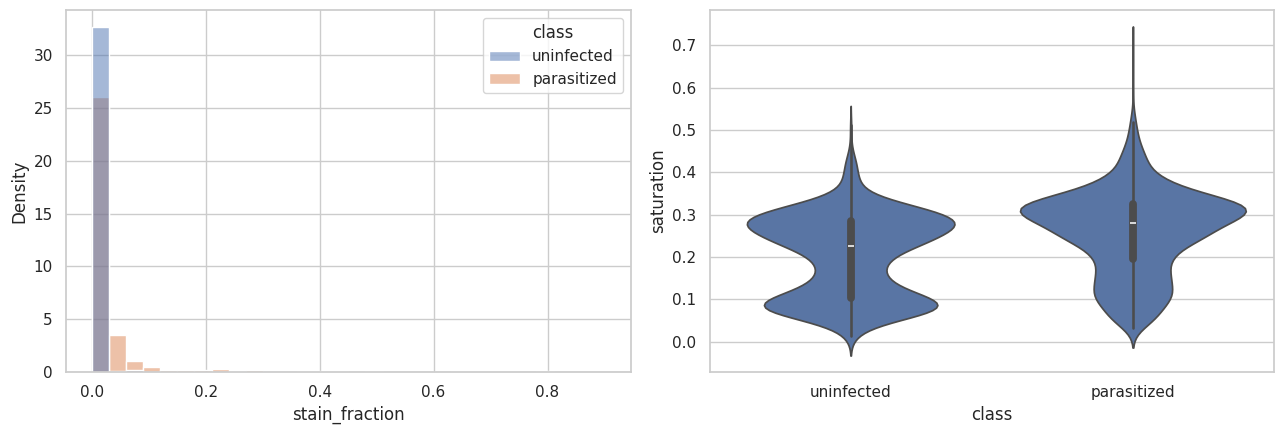

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(
    data=features, x="stain_fraction", hue="class", bins=30, stat="density", common_norm=False, ax=axes[0]
)
sns.violinplot(data=features, x="class", y="saturation", ax=axes[1])
plt.tight_layout()
plt.show()

Correlation between the image features.

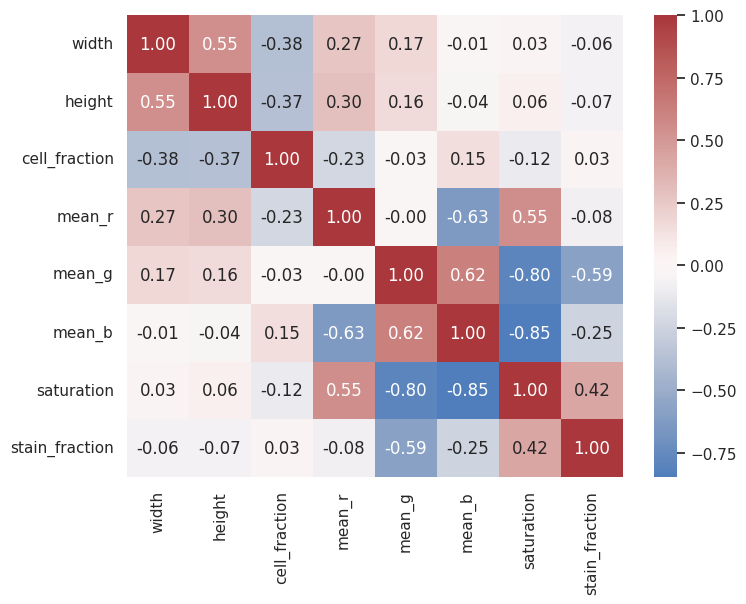

In [10]:
plt.figure(figsize=(8, 6))
sns.heatmap(features.drop(columns="class").corr(), annot=True, fmt=".2f", cmap="vlag", center=0)
plt.show()

Standardised mean difference between classes (Cohen's d, positive means higher in parasitized cells), used to rank how well each feature separates them.

In [11]:
def cohens_d(df, column):
    a = df.loc[df["class"] == "parasitized", column]
    b = df.loc[df["class"] == "uninfected", column]
    pooled = np.sqrt((a.var() + b.var()) / 2)
    return (a.mean() - b.mean()) / pooled


effect_sizes = pd.Series({c: cohens_d(features, c) for c in features.columns.drop("class")})
effect_sizes.sort_values(key=abs, ascending=False).round(3)

,0
mean_g,-0.663
saturation,0.577
stain_fraction,0.457
mean_b,-0.377
cell_fraction,-0.247
height,0.109
width,0.104
mean_r,0.084


In [12]:
tr_p, tr_l, va_p, va_l = P.train_val_split(train_paths, train_labels)
train_ds = P.make_dataset(tr_p, tr_l, shuffle=True)
val_ds = P.make_dataset(va_p, va_l)
test_ds = P.make_dataset(test_paths, test_labels)
len(tr_p), len(va_p), len(test_paths)

(18740, 3308, 5510)

Small CNN configurations.

In [13]:
CNN_BASELINE = {
    "name": "cnn_baseline",
    "arch": "cnn_baseline",
    "augment": False,
    "dropout": 0.0,
    "lr": 1e-3,
    "epochs": 15,
    "unfreeze_last": 0,
    "fine_tune_lr": 0.0,
    "fine_tune_epochs": 0,
}

CNN_IMPROVED = {
    "name": "cnn_improved",
    "arch": "cnn_improved",
    "augment": True,
    "dropout": 0.3,
    "lr": 1e-3,
    "epochs": 25,
    "unfreeze_last": 0,
    "fine_tune_lr": 0.0,
    "fine_tune_epochs": 0,
}

models, histories = {}, {}
for cfg in (CNN_BASELINE, CNN_IMPROVED):
    models[cfg["name"]], histories[cfg["name"]] = M.run_experiment(cfg, train_ds, val_ds)

Epoch 1/15


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


586/586 - 40s - 68ms/step - accuracy: 0.8067 - auc: 0.9026 - loss: 0.3984 - precision: 0.8401 - recall: 0.7576 - val_accuracy: 0.9281 - val_auc: 0.9796 - val_loss: 0.1962 - val_precision: 0.9145 - val_recall: 0.9444 - learning_rate: 0.0010
Epoch 2/15
586/586 - 35s - 60ms/step - accuracy: 0.9469 - auc: 0.9822 - loss: 0.1591 - precision: 0.9583 - recall: 0.9345 - val_accuracy: 0.9498 - val_auc: 0.9864 - val_loss: 0.1445 - val_precision: 0.9627 - val_recall: 0.9359 - learning_rate: 0.0010
Epoch 3/15
586/586 - 16s - 27ms/step - accuracy: 0.9578 - auc: 0.9881 - loss: 0.1267 - precision: 0.9685 - recall: 0.9464 - val_accuracy: 0.9541 - val_auc: 0.9858 - val_loss: 0.1473 - val_precision: 0.9753 - val_recall: 0.9317 - learning_rate: 0.0010
Epoch 4/15
586/586 - 15s - 26ms/step - accuracy: 0.9652 - auc: 0.9924 - loss: 0.1003 - precision: 0.9735 - recall: 0.9565 - val_accuracy: 0.9559 - val_auc: 0.9858 - val_loss: 0.1410 - val_precision: 0.9748 - val_recall: 0.9359 - learning_rate: 5.0000e-04
Epo

MobileNetV2 head-only tuning runs, compared on the validation set.

In [14]:
TUNE_A = {
    "name": "mobilenetv2_lr1e-3_do0.2",
    "arch": "mobilenetv2",
    "augment": True,
    "dropout": 0.2,
    "lr": 1e-3,
    "epochs": 6,
    "unfreeze_last": 0,
    "fine_tune_lr": 0.0,
    "fine_tune_epochs": 0,
}

TUNE_B = {
    "name": "mobilenetv2_lr1e-3_do0.4",
    "arch": "mobilenetv2",
    "augment": True,
    "dropout": 0.4,
    "lr": 1e-3,
    "epochs": 6,
    "unfreeze_last": 0,
    "fine_tune_lr": 0.0,
    "fine_tune_epochs": 0,
}

TUNE_C = {
    "name": "mobilenetv2_lr3e-4_do0.2",
    "arch": "mobilenetv2",
    "augment": True,
    "dropout": 0.2,
    "lr": 3e-4,
    "epochs": 6,
    "unfreeze_last": 0,
    "fine_tune_lr": 0.0,
    "fine_tune_epochs": 0,
}

TUNE_D = {
    "name": "mobilenetv2_lr3e-4_do0.4",
    "arch": "mobilenetv2",
    "augment": True,
    "dropout": 0.4,
    "lr": 3e-4,
    "epochs": 6,
    "unfreeze_last": 0,
    "fine_tune_lr": 0.0,
    "fine_tune_epochs": 0,
}

tuning_rows = []
for cfg in (TUNE_A, TUNE_B, TUNE_C, TUNE_D):
    model, _ = M.run_experiment(cfg, train_ds, val_ds)
    val_metrics = M.evaluate_model(model, val_ds)
    tuning_rows.append({"name": cfg["name"], "lr": cfg["lr"], "dropout": cfg["dropout"], **val_metrics})
    del model
    keras.backend.clear_session()

pd.DataFrame(tuning_rows).drop(columns=["confusion_matrix", "n_samples"]).round(4)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/6
586/586 - 31s - 52ms/step - accuracy: 0.8465 - auc: 0.9266 - loss: 0.3436 - precision: 0.8659 - recall: 0.8200 - val_accuracy: 0.8875 - val_auc: 0.9670 - val_loss: 0.2589 - val_precision: 0.9476 - val_recall: 0.8204 - learning_rate: 0.0010
Epoch 2/6
586/586 - 21s - 36ms/step - accuracy: 0.8963 - auc: 0.9581 - loss: 0.2608 - precision: 0.9115 - recall: 0.8777 - val_accuracy: 0.9117 - val_auc: 0.9712 - val_loss: 0.2310 - val_precision: 0.9283 - val_recall: 0.8924 - learning_rate: 0.0010
Epoch 3/6
586/586 - 21s - 37ms/step - accuracy: 0.9043 - auc: 0.9629 - loss: 0.2451 - precision: 0.9201 - recall: 0.8854 - val_accuracy: 0.8866 - val_auc: 0.9708 - val_loss: 0.2556 - val_precision: 0.9664 - val_recall: 0.8011 - learning_rate: 0.0010
Epoch 4/6
586/586 - 20s - 35ms/step - accuracy: 0.9087 - auc: 0.9648 - loss: 0.2373 - precision: 0.9244 - recall: 0.8902 - val_accuracy: 0.9135 - val_auc: 0.9736 - val_loss: 0.2217 - val_precision: 0.9

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


586/586 - 28s - 48ms/step - accuracy: 0.8367 - auc: 0.9143 - loss: 0.3706 - precision: 0.8538 - recall: 0.8125 - val_accuracy: 0.8972 - val_auc: 0.9645 - val_loss: 0.2611 - val_precision: 0.9415 - val_recall: 0.8470 - learning_rate: 0.0010
Epoch 2/6
586/586 - 22s - 37ms/step - accuracy: 0.8877 - auc: 0.9520 - loss: 0.2802 - precision: 0.9046 - recall: 0.8667 - val_accuracy: 0.8292 - val_auc: 0.9652 - val_loss: 0.3596 - val_precision: 0.9731 - val_recall: 0.6771 - learning_rate: 0.0010
Epoch 3/6
586/586 - 41s - 70ms/step - accuracy: 0.8898 - auc: 0.9529 - loss: 0.2752 - precision: 0.9067 - recall: 0.8689 - val_accuracy: 0.8939 - val_auc: 0.9691 - val_loss: 0.2481 - val_precision: 0.9546 - val_recall: 0.8271 - learning_rate: 5.0000e-04
Epoch 4/6
586/586 - 21s - 37ms/step - accuracy: 0.8887 - auc: 0.9538 - loss: 0.2734 - precision: 0.9068 - recall: 0.8665 - val_accuracy: 0.8803 - val_auc: 0.9697 - val_loss: 0.2640 - val_precision: 0.9666 - val_recall: 0.7878 - learning_rate: 5.0000e-04
Ep

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


586/586 - 29s - 49ms/step - accuracy: 0.8116 - auc: 0.8965 - loss: 0.4058 - precision: 0.8300 - recall: 0.7837 - val_accuracy: 0.8694 - val_auc: 0.9546 - val_loss: 0.3068 - val_precision: 0.9327 - val_recall: 0.7963 - learning_rate: 3.0000e-04
Epoch 2/6
586/586 - 20s - 35ms/step - accuracy: 0.8796 - auc: 0.9463 - loss: 0.2987 - precision: 0.9008 - recall: 0.8531 - val_accuracy: 0.8821 - val_auc: 0.9610 - val_loss: 0.2758 - val_precision: 0.9299 - val_recall: 0.8265 - learning_rate: 3.0000e-04
Epoch 3/6
586/586 - 22s - 37ms/step - accuracy: 0.8906 - auc: 0.9555 - loss: 0.2710 - precision: 0.9099 - recall: 0.8669 - val_accuracy: 0.8978 - val_auc: 0.9677 - val_loss: 0.2512 - val_precision: 0.9312 - val_recall: 0.8591 - learning_rate: 3.0000e-04
Epoch 4/6
586/586 - 22s - 37ms/step - accuracy: 0.8972 - auc: 0.9592 - loss: 0.2600 - precision: 0.9160 - recall: 0.8747 - val_accuracy: 0.8718 - val_auc: 0.9690 - val_loss: 0.2789 - val_precision: 0.9652 - val_recall: 0.7715 - learning_rate: 3.000

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


586/586 - 28s - 48ms/step - accuracy: 0.7852 - auc: 0.8670 - loss: 0.4579 - precision: 0.7991 - recall: 0.7620 - val_accuracy: 0.8570 - val_auc: 0.9477 - val_loss: 0.3222 - val_precision: 0.9288 - val_recall: 0.7733 - learning_rate: 3.0000e-04
Epoch 2/6
586/586 - 22s - 37ms/step - accuracy: 0.8564 - auc: 0.9304 - loss: 0.3357 - precision: 0.8762 - recall: 0.8301 - val_accuracy: 0.8664 - val_auc: 0.9573 - val_loss: 0.2974 - val_precision: 0.9379 - val_recall: 0.7848 - learning_rate: 3.0000e-04
Epoch 3/6
586/586 - 22s - 38ms/step - accuracy: 0.8751 - auc: 0.9438 - loss: 0.3034 - precision: 0.8920 - recall: 0.8536 - val_accuracy: 0.8897 - val_auc: 0.9649 - val_loss: 0.2636 - val_precision: 0.9352 - val_recall: 0.8374 - learning_rate: 3.0000e-04
Epoch 4/6
586/586 - 20s - 35ms/step - accuracy: 0.8827 - auc: 0.9488 - loss: 0.2878 - precision: 0.8997 - recall: 0.8615 - val_accuracy: 0.8773 - val_auc: 0.9669 - val_loss: 0.2772 - val_precision: 0.9650 - val_recall: 0.7830 - learning_rate: 3.000

,name,lr,dropout,accuracy,precision,recall,f1,roc_auc
0,mobilenetv2_lr1e-3_do0.2,0.0010,0.2,0.9135,0.9471,0.8761,0.9102,0.9737
1,mobilenetv2_lr1e-3_do0.4,0.0010,0.4,0.9008,0.9504,0.8458,0.8951,0.9704
2,mobilenetv2_lr3e-4_do0.2,0.0003,0.2,0.8975,0.9563,0.8331,0.8905,0.9703
3,mobilenetv2_lr3e-4_do0.4,0.0003,0.4,0.8912,0.9556,0.8204,0.8829,0.9686


Final MobileNetV2 configuration: head training followed by fine-tuning of the last backbone layers.

In [15]:
MOBILENET = {
    "name": "mobilenetv2",
    "arch": "mobilenetv2",
    "augment": True,
    "dropout": 0.3,
    "lr": 1e-3,
    "epochs": 8,
    "unfreeze_last": 30,
    "fine_tune_lr": 1e-5,
    "fine_tune_epochs": 8,
}

models[MOBILENET["name"]], histories[MOBILENET["name"]] = M.run_experiment(MOBILENET, train_ds, val_ds)

Epoch 1/8


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


586/586 - 28s - 48ms/step - accuracy: 0.8390 - auc: 0.9180 - loss: 0.3627 - precision: 0.8544 - recall: 0.8172 - val_accuracy: 0.8688 - val_auc: 0.9667 - val_loss: 0.2861 - val_precision: 0.9628 - val_recall: 0.7672 - learning_rate: 0.0010
Epoch 2/8
586/586 - 22s - 37ms/step - accuracy: 0.8866 - auc: 0.9528 - loss: 0.2774 - precision: 0.9053 - recall: 0.8635 - val_accuracy: 0.9027 - val_auc: 0.9703 - val_loss: 0.2375 - val_precision: 0.9464 - val_recall: 0.8537 - learning_rate: 0.0010
Epoch 3/8
586/586 - 22s - 37ms/step - accuracy: 0.8981 - auc: 0.9577 - loss: 0.2611 - precision: 0.9139 - recall: 0.8791 - val_accuracy: 0.9126 - val_auc: 0.9721 - val_loss: 0.2307 - val_precision: 0.9378 - val_recall: 0.8839 - learning_rate: 0.0010
Epoch 4/8
586/586 - 20s - 35ms/step - accuracy: 0.8973 - auc: 0.9582 - loss: 0.2598 - precision: 0.9137 - recall: 0.8776 - val_accuracy: 0.8927 - val_auc: 0.9714 - val_loss: 0.2445 - val_precision: 0.9643 - val_recall: 0.8156 - learning_rate: 0.0010
Epoch 5/8


Training and validation curves for each model.

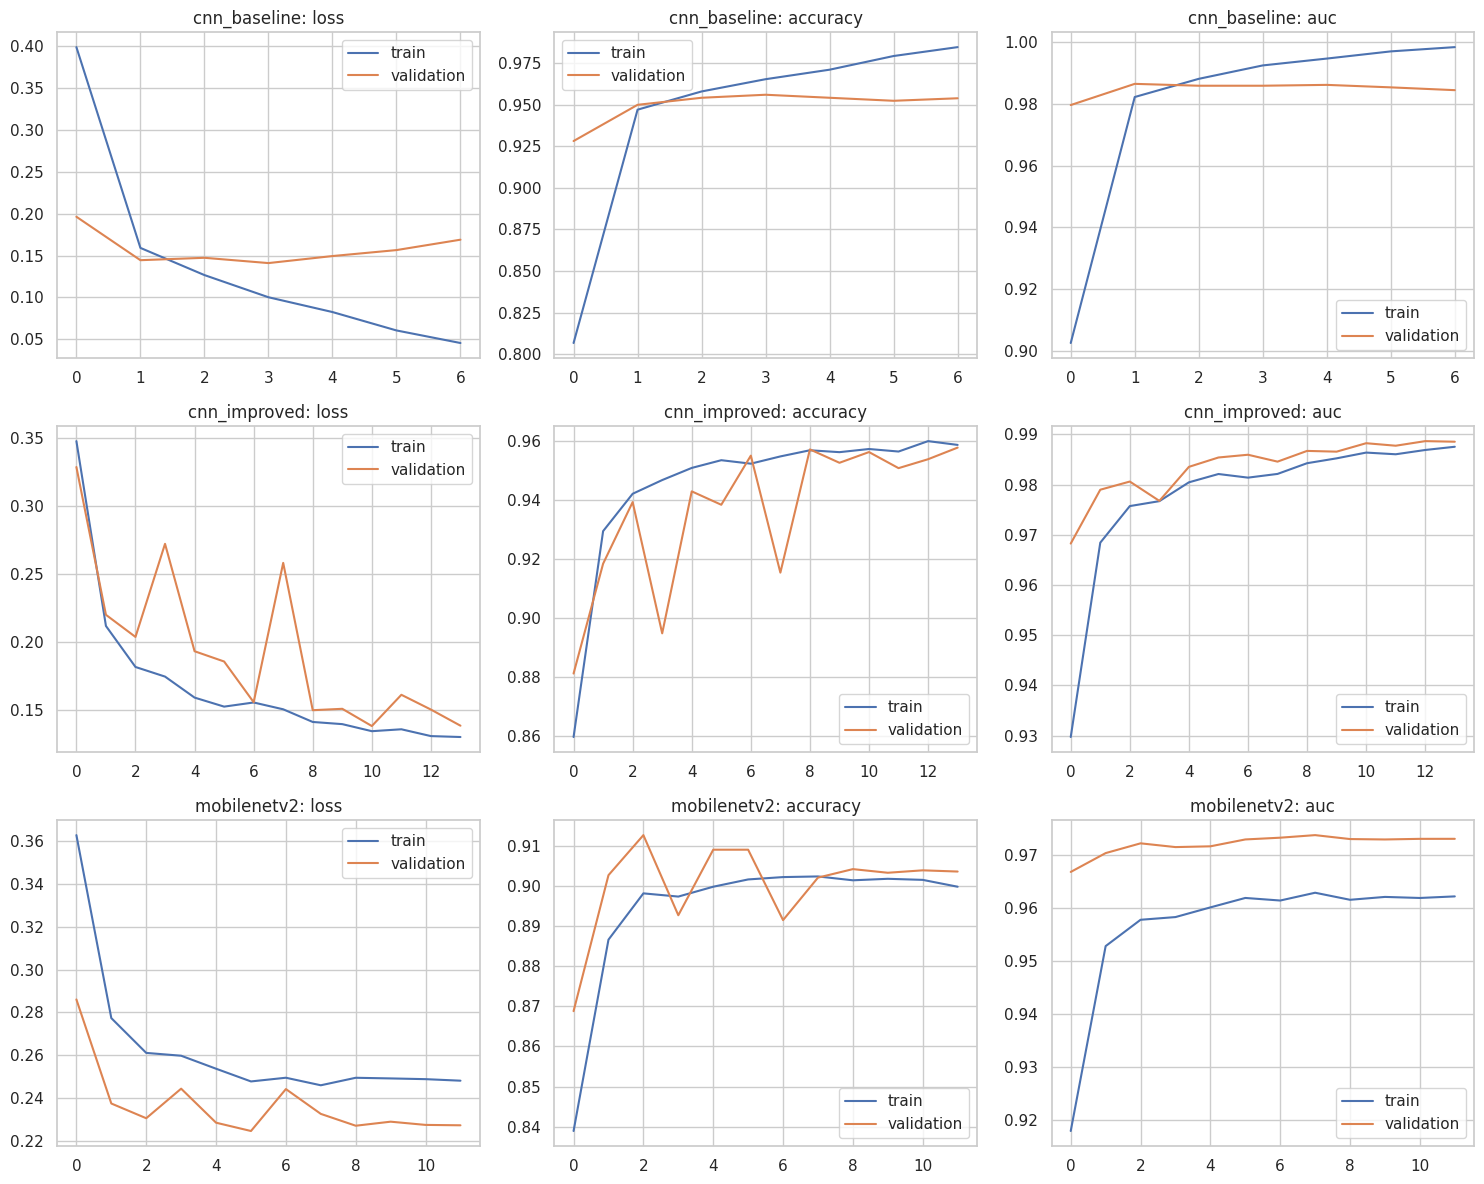

In [16]:
fig, axes = plt.subplots(len(histories), 3, figsize=(15, 4 * len(histories)))
for row, (name, history) in zip(axes, histories.items()):
    for ax, key in zip(row, ("loss", "accuracy", "auc")):
        ax.plot(history[key], label="train")
        ax.plot(history[f"val_{key}"], label="validation")
        ax.set_title(f"{name}: {key}")
        ax.legend()
plt.tight_layout()
plt.show()

Test-set evaluation with accuracy, precision, recall, F1 and ROC-AUC. Parasitized is the positive class.

In [17]:
results, predictions = {}, {}
for name, model in models.items():
    y_true, y_prob = M.collect_predictions(model, test_ds)
    predictions[name] = (y_true, y_prob)
    results[name] = M.compute_metrics(y_true, y_prob)

summary = pd.DataFrame(
    {n: {k: v for k, v in r.items() if k not in ("confusion_matrix", "n_samples")} for n, r in results.items()}
).T
summary.to_csv(config.MODELS_DIR / "model_comparison.csv")
summary.round(4)

,accuracy,precision,recall,f1,roc_auc
cnn_baseline,0.9555,0.9683,0.9419,0.9549,0.9859
cnn_improved,0.9555,0.9747,0.9354,0.9546,0.9898
mobilenetv2,0.9080,0.9475,0.8639,0.9037,0.9698


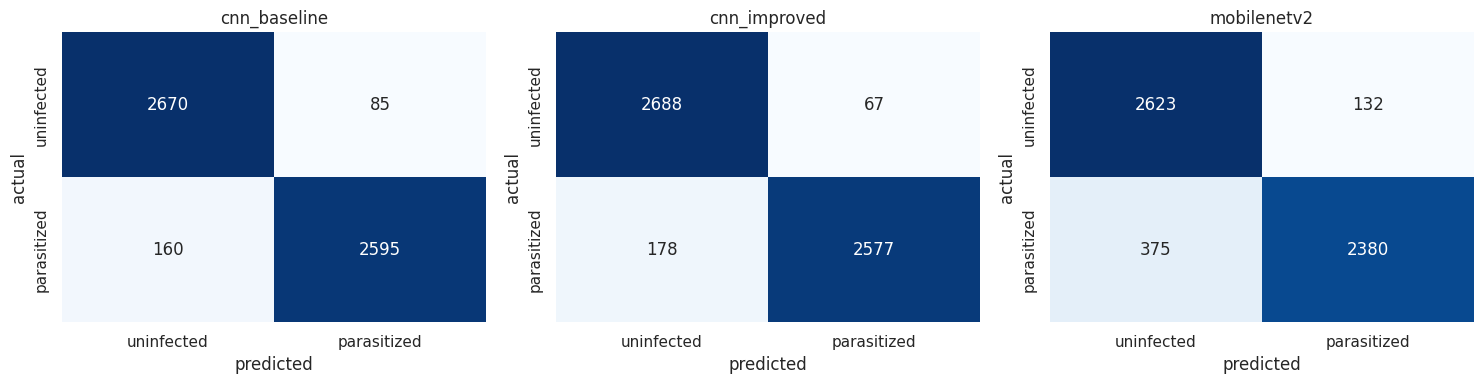

In [18]:
fig, axes = plt.subplots(1, len(results), figsize=(5 * len(results), 4))
for ax, (name, r) in zip(axes, results.items()):
    sns.heatmap(
        np.array(r["confusion_matrix"]),
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=config.CLASS_NAMES,
        yticklabels=config.CLASS_NAMES,
        ax=ax,
    )
    ax.set(title=name, xlabel="predicted", ylabel="actual")
plt.tight_layout()
plt.show()

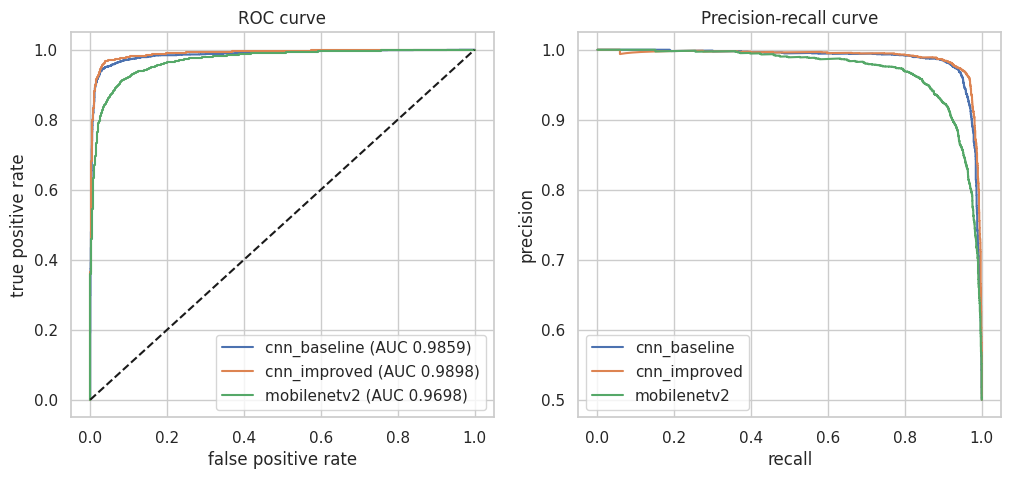

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, (y_true, y_prob) in predictions.items():
    fpr, tpr, _ = skm.roc_curve(y_true, y_prob)
    precision, recall, _ = skm.precision_recall_curve(y_true, y_prob)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC {results[name]['roc_auc']:.4f})")
    axes[1].plot(recall, precision, label=name)
axes[0].plot([0, 1], [0, 1], "k--")
axes[0].set(title="ROC curve", xlabel="false positive rate", ylabel="true positive rate")
axes[1].set(title="Precision-recall curve", xlabel="recall", ylabel="precision")
axes[0].legend()
axes[1].legend()
plt.show()

In [20]:
y_true, y_prob = predictions["mobilenetv2"]
print(skm.classification_report(y_true, (y_prob >= 0.5).astype(int), target_names=config.CLASS_NAMES, digits=4))

              precision    recall  f1-score   support

  uninfected     0.8749    0.9521    0.9119      2755
 parasitized     0.9475    0.8639    0.9037      2755

    accuracy                         0.9080      5510
   macro avg     0.9112    0.9080    0.9078      5510
weighted avg     0.9112    0.9080    0.9078      5510



Effect of the decision threshold on the final model. Lowering it trades precision for recall on parasitized cells.

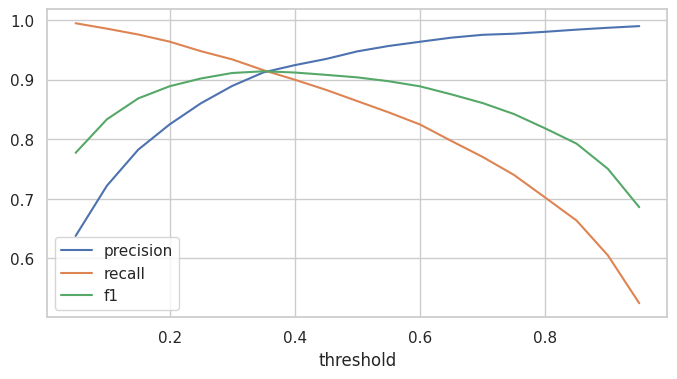

In [21]:
rows = []
for threshold in np.linspace(0.05, 0.95, 19):
    m = M.compute_metrics(y_true, y_prob, threshold)
    rows.append({"threshold": threshold, "precision": m["precision"], "recall": m["recall"], "f1": m["f1"]})
pd.DataFrame(rows).set_index("threshold").plot(figsize=(8, 4))
plt.show()

Parasitized test cells the final model missed.

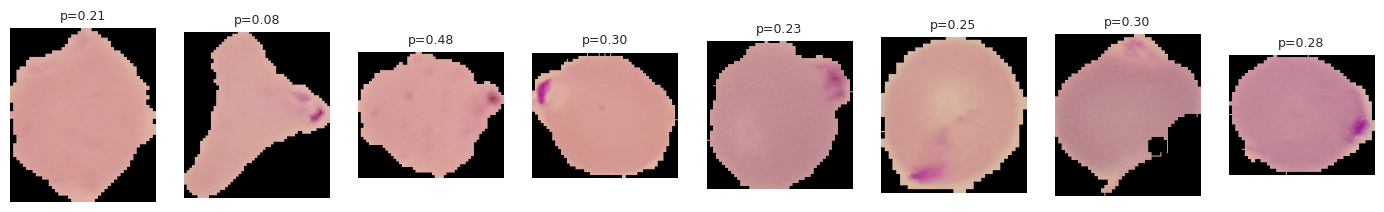

In [22]:
y_pred = (y_prob >= 0.5).astype(int)
missed = np.where((y_true == 1) & (y_pred == 0))[0][:8]
fig, axes = plt.subplots(1, max(len(missed), 1), figsize=(2.2 * max(len(missed), 1), 2.6), squeeze=False)
for ax, i in zip(axes[0], missed):
    ax.imshow(Image.open(test_paths[i]))
    ax.set_title(f"p={y_prob[i]:.2f}", fontsize=9)
    ax.axis("off")
plt.show()

The final model is registered as version 1 so the API can serve it and retraining can build on it.

In [23]:
version = R.register_model(models["mobilenetv2"], results["mobilenetv2"], name="mobilenetv2")
print(version, sorted(p.name for p in config.MODELS_DIR.iterdir()))

1 ['.gitkeep', 'malaria_v1.keras', 'model_comparison.csv', 'registry.json']


In [24]:
import shutil

shutil.make_archive("/content/models_export", "zip", config.MODELS_DIR)
files.download("/content/models_export.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>